# Predicting House Prices Using Regression

## Business Problem: A real estate analyst wants to understand how neighbourhood characteristics relate to house prices and build a model that estimates property values from available housing data.

### Objective: To develop a regression model that uses housing and neighbourhood features to predict median house values for given suburb

Target Variable: MEDV - Median owner occupied home value , originally recorded in thousands of US dollars.

Machine learning task: Supervised learning - Regression.

In [ ]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Machine Learining models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

In [ ]:
# loading the data set
df = pd.read_csv('/content/boston.csv')

In [ ]:
# Preview the data set
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [ ]:
# Dataset information = shows Missing and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [ ]:
# Summary statistics
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [ ]:
# check for missing values
df.isnull().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


Our data is relatively clean - No missing values and the data types are float and

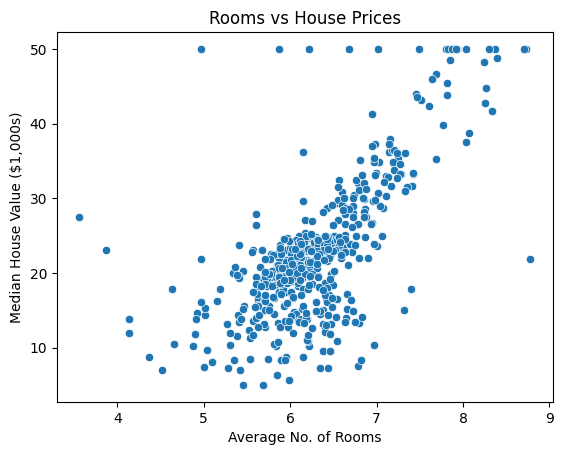

In [ ]:
# Visualize relationship between the no. of rooms (rm) and MEDV
sns.scatterplot(x='RM', y='MEDV', data=df)
plt.xlabel('Average No. of Rooms')
plt.ylabel('Median House Value ($1,000s)')
plt.title('Rooms vs House Prices')
plt.show()

The relationship between MEDV and the RM is linear (Positively correlated)- An increase in rooms results to increase in the prices.


In [ ]:
# Seperate the relevant features and targets
X = df.drop('MEDV', axis=1) # FEATURES/ PREDICTORS - Model is not given the answer while it starting to predict
y = df['MEDV'] # VARIEBLES TO PREDICT

In [ ]:
# Spliting the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# random state allows the results to be reproduceable
# splitting the data into 80% train and 20% test

In [ ]:
# Training the linear regression model
# Initialize the model
model = LinearRegression()
# Fit the model to the training data
model.fit(X_train, y_train) # understand the data and come up with the equation
# by estimating the intercept and coeffiecient from the training data.

LinearRegression()

In [ ]:
# Make predictions
y_pred = model.predict(X_test)# x test is the data which we witheld while training.

In [ ]:
# Seee the results
result = pd.DataFrame(
    {'Actual Price ($1,000s)': y_test.values,
     'Predicted Price ($1,000s)': y_pred})
print(result.head(10).round(2))

   Actual Price ($1,000s)  Predicted Price ($1,000s)
0                    23.6                      29.00
1                    32.4                      36.03
2                    13.6                      14.82
3                    22.8                      25.03
4                    16.1                      18.77
5                    20.0                      23.25
6                    17.8                      17.66
7                    14.0                      14.34
8                    19.6                      23.01
9                    16.8                      20.63


In [ ]:
# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)
# printing the model evaluation result
print(f'Mean Absolute Error: {mae:.2f}') # .2 is in 2 decimal places
print(f'Mean Squared Error:{rmse:.2f}')
print(f'R-squared:{r2:.2f}')


Mean Absolute Error: 3.19
Mean Squared Error:4.93
R-squared:0.67


### 1. MAE = 3.19
Our prediction differs from the actual house values by an average absolute amount of approximately $3,190, using the dataset's original units. This does not mean every prediction is wrong by that amount.

### 2. RMSE = 4.93
RSME penalizes larger errors more heavily than MAE. Since RMSE is larger than MAE, some predictions has larger errors than others

### 3. R-Squared = 0.67
Our model accounts for approximately 67% of the variation in house value in the test-set mean. The remaining variation is not captured by the model.
This does not mean that the 67% individual predictions are correct.


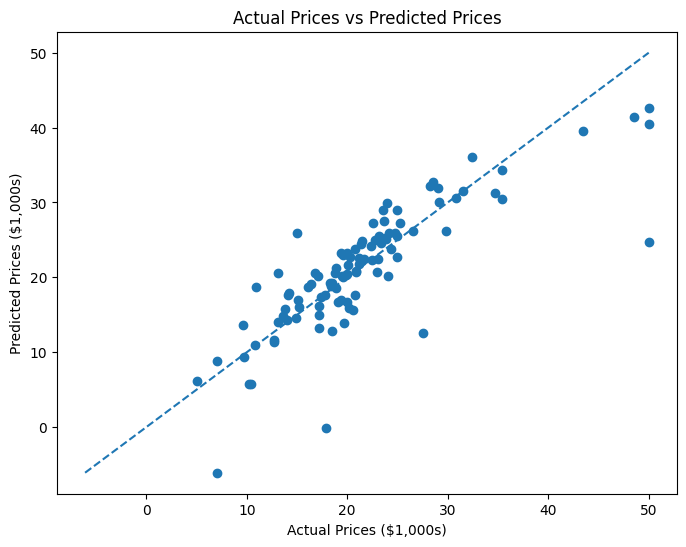

In [ ]:
# Visualize the actual vs the predicted prices
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred)

# Reference line for perfect prediction
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)
plt.xlabel('Actual Prices ($1,000s)')
plt.ylabel('Predicted Prices ($1,000s)')
plt.title('Actual Prices vs Predicted Prices')
plt.show()

- Each point represent one test observation
- The dashed line represents perfect predictions
- Points closed to the line represent more accurate predictions
- Points far from the line indicate larger prediction errors

In [ ]:
# Examining the coefficient (X variables eg room)
Coefficients = pd.DataFrame(
    {
        'Features': X.columns,
        'Coefficients': model.coef_

    })
Coefficients ['Absolute Coefficient'] = (
    Coefficients ['Coefficients'].abs()
)
Coeffiencts = Coefficients.sort_values(
    by='Absolute Coefficient', ascending=False
)
print(Coefficients.round(2))

   Features  Coefficients  Absolute Coefficient
0      CRIM         -0.11                  0.11
1        ZN          0.03                  0.03
2     INDUS          0.04                  0.04
3      CHAS          2.78                  2.78
4       NOX        -17.20                 17.20
5        RM          4.44                  4.44
6       AGE         -0.01                  0.01
7       DIS         -1.45                  1.45
8       RAD          0.26                  0.26
9       TAX         -0.01                  0.01
10  PTRATIO         -0.92                  0.92
11        B          0.01                  0.01
12    LSTAT         -0.51                  0.51
